# 🔍 Interpolation & Rotation — implemented from scratch

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/negarsh76/Digital-Image-Processing/blob/main/notebooks/02_interpolation_and_rotation.ipynb)

Image resizing with **nearest-neighbour**, **bilinear** and **bicubic** interpolation, all written from scratch with vectorised NumPy (no `cv2.resize`), and image rotation by **inverse mapping**. Each method is checked numerically with PSNR.

In [1]:
# On Colab, uncomment:
# !pip -q install scikit-image opencv-python-headless

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import data, img_as_float
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "image.cmap": "gray"})
ASSETS = Path("../assets"); ASSETS.mkdir(exist_ok=True)

def show(images, titles, ncols=None, figsize=None, save=None, cmap="gray"):
    """Plot a row/grid of images with titles; optionally save to assets/."""
    n = len(images); ncols = ncols or n; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize or (3.2 * ncols, 3.2 * nrows))
    for ax, im, t in zip(np.ravel(axes), images, titles):
        ax.imshow(im, cmap=None if im.ndim == 3 else cmap); ax.set_title(t); ax.axis("off")
    for ax in np.ravel(axes)[n:]: ax.axis("off")
    fig.tight_layout()
    if save: fig.savefig(ASSETS / save, bbox_inches="tight", dpi=120)
    plt.show()

def psnr(ref, img):
    mse = np.mean((np.asarray(ref, float) - np.asarray(img, float)) ** 2)
    return 10 * np.log10(1.0 / mse) if mse > 0 else np.inf


In [3]:
img = img_as_float(data.chelsea()[..., 0])  # grayscale cat, values in [0, 1]
print(img.shape)

(300, 451)


## Inverse mapping
For every pixel $(r', c')$ of the **output** image we ask *where it came from* in the input, $(r, c) = (r'/s_y,\ c'/s_x)$, and interpolate the input there. That way the output has no holes.

In [4]:
def _coords(h_in, w_in, h_out, w_out):
    # pixel-centre alignment (same convention as OpenCV / skimage)
    r = (np.arange(h_out) + 0.5) * h_in / h_out - 0.5
    c = (np.arange(w_out) + 0.5) * w_in / w_out - 0.5
    return np.meshgrid(r, c, indexing="ij")

def resize_nearest(im, h, w):
    R, C = _coords(*im.shape, h, w)
    R = np.clip(np.round(R), 0, im.shape[0] - 1).astype(int)
    C = np.clip(np.round(C), 0, im.shape[1] - 1).astype(int)
    return im[R, C]

def resize_bilinear(im, h, w):
    R, C = _coords(*im.shape, h, w)
    R = np.clip(R, 0, im.shape[0] - 1); C = np.clip(C, 0, im.shape[1] - 1)
    r0, c0 = np.floor(R).astype(int), np.floor(C).astype(int)
    r1, c1 = np.minimum(r0 + 1, im.shape[0] - 1), np.minimum(c0 + 1, im.shape[1] - 1)
    dr, dc = R - r0, C - c0
    top = im[r0, c0] * (1 - dc) + im[r0, c1] * dc
    bot = im[r1, c0] * (1 - dc) + im[r1, c1] * dc
    return top * (1 - dr) + bot * dr

def cubic_kernel(x, a=-0.5):
    """Keys' cubic convolution kernel."""
    x = np.abs(x)
    return np.where(x <= 1, (a + 2) * x**3 - (a + 3) * x**2 + 1,
           np.where(x < 2, a * x**3 - 5 * a * x**2 + 8 * a * x - 4 * a, 0.0))

def resize_bicubic(im, h, w):
    R, C = _coords(*im.shape, h, w)
    r0, c0 = np.floor(R).astype(int), np.floor(C).astype(int)
    out = np.zeros((h, w))
    for i in range(-1, 3):                       # 4×4 neighbourhood
        wr = cubic_kernel(R - (r0 + i))
        ri = np.clip(r0 + i, 0, im.shape[0] - 1)
        for j in range(-1, 3):
            wc = cubic_kernel(C - (c0 + j))
            cj = np.clip(c0 + j, 0, im.shape[1] - 1)
            out += wr * wc * im[ri, cj]
    return np.clip(out, 0, 1)

## Zoom ×4 on a small crop

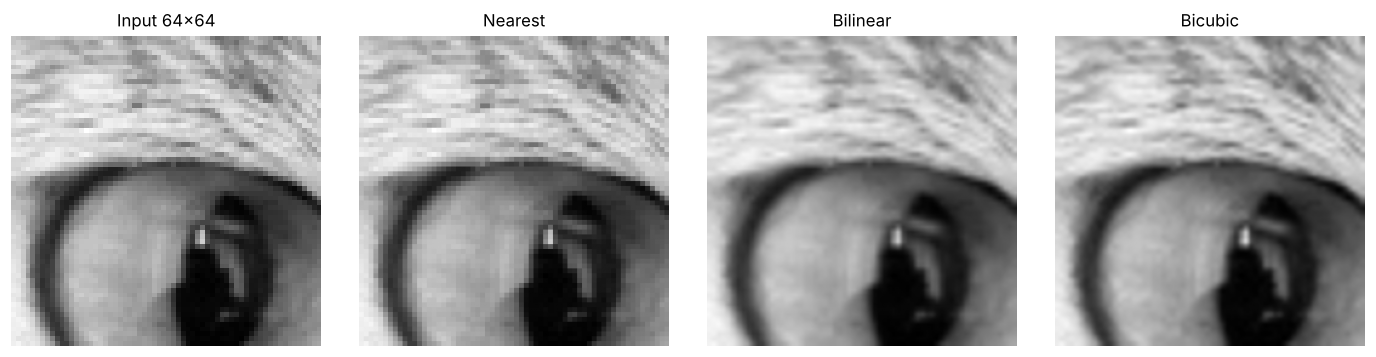

In [5]:
crop = img[60:124, 130:194]                      # 64×64 patch around the eye
H, W = crop.shape[0] * 4, crop.shape[1] * 4
zooms = [resize_nearest(crop, H, W), resize_bilinear(crop, H, W), resize_bicubic(crop, H, W)]
show([crop] + zooms, ["Input 64×64", "Nearest", "Bilinear", "Bicubic"], save="interp_zoom.png")

## Quantitative check: down-sample ×4, then up-sample back
We shrink the image by averaging 4×4 blocks (so there is no aliasing), then enlarge it again with each method. A higher PSNR against the original means the method recovers more detail.

In [6]:
h, w = (s // 4 * 4 for s in img.shape)
img = img[:h, :w]
small = img.reshape(h // 4, 4, w // 4, 4).mean(axis=(1, 3))
for name, f in [("Nearest", resize_nearest), ("Bilinear", resize_bilinear), ("Bicubic", resize_bicubic)]:
    up = f(small, *img.shape)
    print(f"{name:9s} PSNR = {psnr(img, up):5.2f} dB")

# our bicubic vs OpenCV's (same Keys kernel, a = -0.5 vs OpenCV -0.75)
import cv2
cv = cv2.resize(small.astype(np.float32), img.shape[::-1], interpolation=cv2.INTER_CUBIC)
print(f"OpenCV bicubic PSNR = {psnr(img, np.clip(cv, 0, 1)):5.2f} dB")

Nearest   PSNR = 28.22 dB
Bilinear  PSNR = 29.21 dB
Bicubic   PSNR = 29.91 dB
OpenCV bicubic PSNR = 30.06 dB


## Rotation by inverse mapping
For each output pixel we apply the **inverse** rotation about the image centre and sample the input with bilinear interpolation. Pixels that land outside are left black.

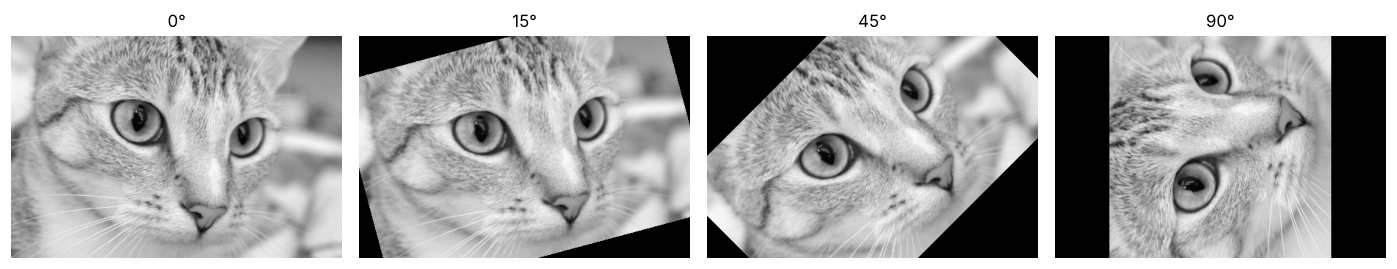

In [7]:
def rotate(im, angle_deg):
    t = np.deg2rad(angle_deg)
    h, w = im.shape
    cy, cx = (h - 1) / 2, (w - 1) / 2
    rr, cc = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    y, x = rr - cy, cc - cx
    src_r = np.cos(t) * y + np.sin(t) * x + cy     # inverse rotation
    src_c = -np.sin(t) * y + np.cos(t) * x + cx
    valid = (src_r >= 0) & (src_r <= h - 1) & (src_c >= 0) & (src_c <= w - 1)
    r0 = np.clip(np.floor(src_r).astype(int), 0, h - 2); c0 = np.clip(np.floor(src_c).astype(int), 0, w - 2)
    dr, dc = np.clip(src_r - r0, 0, 1), np.clip(src_c - c0, 0, 1)
    out = (im[r0, c0] * (1 - dr) * (1 - dc) + im[r0 + 1, c0] * dr * (1 - dc)
           + im[r0, c0 + 1] * (1 - dr) * dc + im[r0 + 1, c0 + 1] * dr * dc)
    return np.where(valid, out, 0)

show([img, rotate(img, 15), rotate(img, 45), rotate(img, 90)], ["0°", "15°", "45°", "90°"], save="rotation.png")

### Why interpolation matters: rotate 12 × 30° = 360°
Each rotation resamples the image, so errors build up. The two methods fail in different ways. Nearest-neighbour keeps the fur texture but breaks edges into jagged staircases. Bilinear keeps edges smooth but blurs fine detail, because each pass averages neighbouring pixels. PSNR alone doesn't capture that trade-off, which is why higher-order kernels such as bicubic or Lanczos are used for repeated warps.

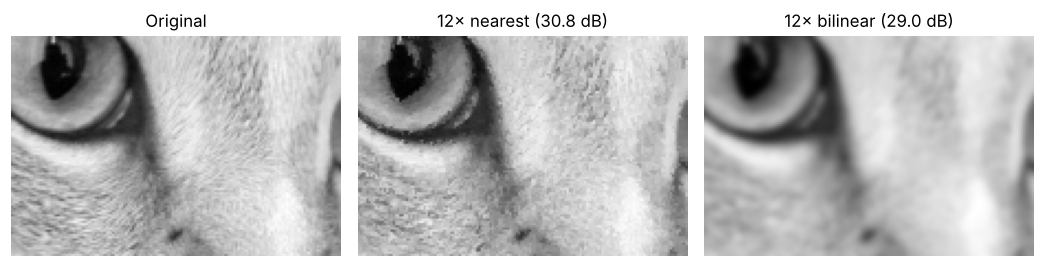

In [8]:
def rotate_nn(im, a):
    t = np.deg2rad(a); h, w = im.shape; cy, cx = (h - 1) / 2, (w - 1) / 2
    rr, cc = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    sr = np.round(np.cos(t) * (rr - cy) + np.sin(t) * (cc - cx) + cy).astype(int)
    sc = np.round(-np.sin(t) * (rr - cy) + np.cos(t) * (cc - cx) + cx).astype(int)
    ok = (sr >= 0) & (sr < h) & (sc >= 0) & (sc < w)
    return np.where(ok, im[np.clip(sr, 0, h - 1), np.clip(sc, 0, w - 1)], 0)

a, b = img.copy(), img.copy()
for _ in range(12):
    a, b = rotate_nn(a, 30), rotate(b, 30)
m = slice(100, 200), slice(150, 300)
show([img[m], a[m], b[m]], ["Original", f"12× nearest ({psnr(img[m], a[m]):.1f} dB)", f"12× bilinear ({psnr(img[m], b[m]):.1f} dB)"],
     save="rotation_accumulated.png")